# Overview

Based on the official transverse-field Ising model (TFIM) simulation tutorial, this notebook computes the two-point correlation function $\langle Z_i Z_j \rangle$ and their connected version $\langle Z_i Z_j\rangle - \langle Z_i\rangle\langle Z_j\rangle$ of the first-order Lie Trotterization. The results are shown as heatmaps to show how does information spread along the chain.

# Base Model

First, we import the required libraries. `seaborn`, `matplotlib.animation` and `IPython.display` are used to create heatmap animation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.animation as animation
from IPython.display import HTML

from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator

The Hamiltonian of transverse-field Ising model (TFIM) is given by
$$
\hat{H} = -J \sum_{i=0}^{N-2} Z_i Z_{i+1} \; - \; h \sum_{i=0}^{N-1} X_i,
$$

The code from the official challenge 3 tutorial is used to define the Hamiltonian. Same as in the tutorial, a chain of $N = 4$ spins with coupling $J = 1$ and field $h = 1$ is used to keep the model simple.

In [2]:
def tfim_hamiltonian(num_qubits, J=1.0, h=1.0):
    """Transverse-field Ising Hamiltonian on an open chain as a SparsePauliOp."""
    terms = []

    # Interaction terms: -J * Z_i Z_{i+1}
    for i in range(num_qubits - 1):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        pauli[i + 1] = "Z"
        # Qiskit reads Pauli strings right-to-left (qubit 0 is the rightmost char)
        terms.append(("".join(reversed(pauli)), -J))

    # Field terms: -h * X_i
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "X"
        terms.append(("".join(reversed(pauli)), -h))

    return SparsePauliOp.from_list(terms)


num_qubits = 4
J, h = 1.0, 1.0
H = tfim_hamiltonian(num_qubits, J, h)

print(f"TFIM on {num_qubits} qubits (J={J}, h={h}):")
print(H)

TFIM on 4 qubits (J=1.0, h=1.0):
SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'IIIX', 'IIXI', 'IXII', 'XIII'],
              coeffs=[-1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j])


The code below defines the trotter evolution circuit.

In [3]:
def trotter_evolution_circuit(H, num_qubits, dt, n_steps, order=1):
    """Prepare |00..0> and apply n_steps Trotter steps of size dt."""
    if order == 1:
        synth = LieTrotter(reps=1)
    else:
        synth = SuzukiTrotter(order=order, reps=1)

    qc = QuantumCircuit(num_qubits)
    # initial state |00..0> is the default; add an explicit barrier for clarity
    qc.barrier()

    step = PauliEvolutionGate(H, time=dt, synthesis=synth)
    # for _ in range(n_steps):
            #     qc.append(step, range(num_qubits))

    # Above is the original code from the tutorial, but I found that it actually produces a result we didn't want (at least on my laptop).
    # If we do not synthesize manually, PauliEvolutionGate will use the exact matrix form instead of doing trotterlization,
    # resulting in extremely low errors (around 10^-15) regardless of the value of dt.
    # So we manually wrote synthesize here.
    trotter_step = synth.synthesize(step)
    for _ in range(n_steps):
        qc.compose(trotter_step, inplace=True)

    return qc

estimator = StatevectorEstimator()

# Correlation and Connected Correlation Function

Our correlation function is

$$
\langle Z_i Z_j \rangle = \langle \psi | Z_i Z_j | \psi \rangle.
$$

And the operator is:
$$
\begin{align*}
Z_i Z_j
&= (I \otimes \cdots \otimes \underset{i}{Z} \otimes \cdots \otimes I ) (I \otimes \cdots \otimes \underset{j}{Z} \otimes \cdots \otimes I )
\\
&= I \otimes \cdots \otimes \underset{i}{Z} \otimes \cdots \otimes I \otimes \cdots \otimes \underset{j}{Z} \otimes \cdots \otimes I
\end{align*}
$$

Besides from the correlation function, we also calculate the connected correlation function $\langle Z_i Z_j\rangle - \langle Z_i\rangle\langle Z_j\rangle$. This is the covariance of the expectation values of single $Z_i$ and $Z_j$ operator, and it helps rule out the effects of the qubits' individual behavior, revealing the true connections between them.

To calculate the connected correlation function, we also need to construct the single $Z$ operator $Z_i$. The code below defines the single $Z$ operator and the two-point correlation operator.

In [4]:
def singleZ_op(num_qubits, site):
    pauli = ["I"] * num_qubits
    pauli[site] = "Z"
    return SparsePauliOp("".join(reversed(pauli)))

def correlation_op(num_qubits, site1, site2):
    pauli = ["I"] * num_qubits
    if site1 != site2:
        pauli[site1] = "Z"
        pauli[site2] = "Z"
    return SparsePauliOp("".join(reversed(pauli)))

We specifically listed the case where `site1` and `site2` are the same, which is when the correlation of a qubit and itself is calculated, because applying $Z$ on the same qubit twice will yield $I$.

Then, we carry out trotterized time evolution.

In [5]:
dt=0.1 # fixed dt = 0.1 second
max_steps = int(6*1/dt) # fixed time interval = 6.0 seconds

times = np.array([n * dt for n in range(max_steps + 1)])

# creating empty result matrices
correlation = np.zeros(((max_steps + 1, num_qubits, num_qubits)))
singleZ = np.zeros((max_steps + 1, num_qubits))

for n in range(max_steps + 1):
    
    circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=n)

    for s1 in range(num_qubits):

        # single Z
        sZ = singleZ_op(num_qubits, s1)
        Zresult = estimator.run([(circ, sZ)]).result()
        singleZ[n][s1] = (float(Zresult[0].data.evs))

        for s2 in range(s1, num_qubits, 1):

            # correlation function
            cor = correlation_op(num_qubits, s1, s2)
            result = estimator.run([(circ, cor)]).result()

            #correlation[n][s1][s2] and correlation[n][s2][s1] are the same, since Z_i are diagonal matrices, and diagonal matrices can commute.
            correlation[n][s1][s2] = correlation[n][s2][s1] = (float(result[0].data.evs))

Then we calculate the connected correlation function $\langle Z_i Z_j\rangle - \langle Z_i\rangle\langle Z_j\rangle$.

In [6]:
connected_correlation = np.zeros(((max_steps + 1, num_qubits, num_qubits)))
for n in range(max_steps + 1):
    for s1 in range(num_qubits):
        for s2 in range(num_qubits):
            connected_correlation[n][s1][s2] = correlation[n][s1][s2] - singleZ[n][s1] * singleZ[n][s2]

# Results

We first plot the result as an animation of two heatmaps to directly see the change in correlation function and its connected version through time.

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
sns.heatmap(
    correlation[0],
    ax=ax1,
    square=True,
    cmap='PuOr',
    vmin=-1,
    vmax=1,
    annot=True,
    linewidths=0.5
)
sns.heatmap(
    connected_correlation[0],
    ax=ax2,
    square=True,
    cmap='PuOr',
    vmin=-1,
    vmax=1,
    annot=True,
    linewidths=0.5
)

title1 = ax1.set_title(f"Correlation (t={times[0]:.2f})")
title2 = ax2.set_title(f"Connected Correlation (t={times[0]:.2f})")

mesh1 = ax1.collections[0]
mesh2 = ax2.collections[0]

def update(frame):
    mesh1.set_array(correlation[frame].flatten())
    mesh2.set_array(connected_correlation[frame].flatten())

    for i, text in enumerate(ax1.texts):
        row, col = divmod(i, correlation.shape[1])
        text.set_text(f"{correlation[frame][row, col]:.2f}")
        text.set_color("white" if abs(correlation[frame][row, col]) > 0.5 else "black")

    for i, text in enumerate(ax2.texts):
        row, col = divmod(i, connected_correlation.shape[1])
        text.set_text(f"{connected_correlation[frame][row, col]:.2f}")
        text.set_color("white" if abs(connected_correlation[frame][row, col]) > 0.5 else "black")

    title1.set_text(f"Correlation (t={times[frame]:.1f})")
    title2.set_text(f"Connected Correlation (t={times[frame]:.1f})")
    return mesh1, mesh2, title1, title2

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(times),
    interval=200,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())

To investigate the relationship between the distance between qubits and the change in their correlation over time more clearly, we take the average value of the correlation function and the connected correlation of those with the same distance between qubits, and plot them with time as two heatmaps.

In [8]:
def distance_average(matrices):
    matrices = np.asarray(matrices)
    steps, qubits, _ = matrices.shape
    result = np.zeros((steps, qubits))
    for step, matrix in enumerate(matrices):
        for d in range(qubits):
            pairs = np.diag(matrix, k=d)
            result[step, d] = np.mean(pairs)
    return result

connected_dt = distance_average(connected_correlation)
correlation_dt = distance_average(correlation)

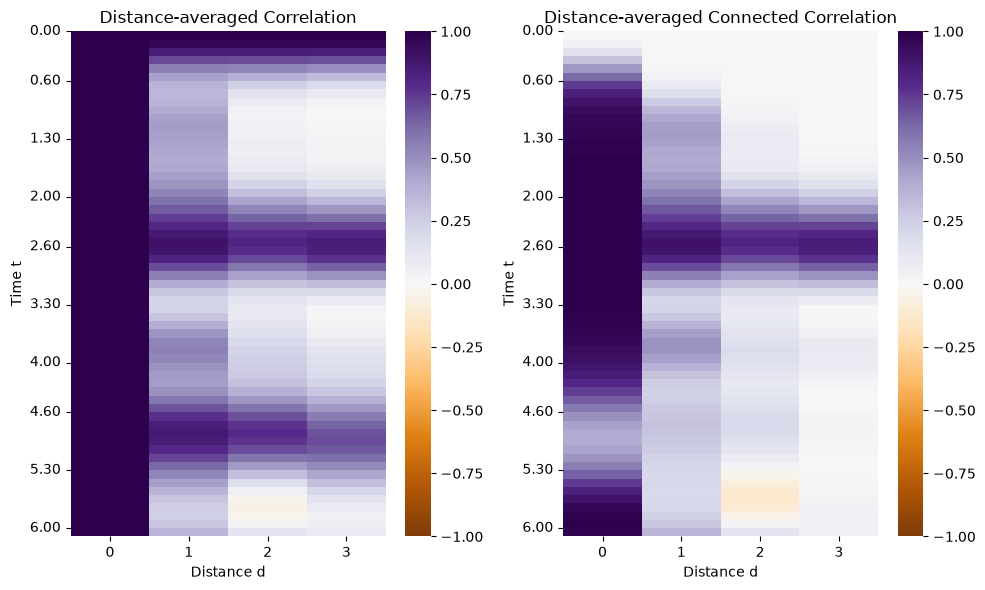

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

sns.heatmap(
    correlation_dt,
    ax=ax1,
    cmap="PuOr",
    vmin=-1,
    vmax=1,
)
sns.heatmap(
    connected_dt,
    ax=ax2,
    cmap="PuOr",
    vmin=-1,
    vmax=1,
)

tick_ids = np.linspace(0, len(times)-1, 10, dtype=int)
ax1.set_yticks(tick_ids)
ax2.set_yticks(tick_ids)

# converting steps into time (seconds) for display
ax1.set_yticklabels(
    [f"{times[i]:.2f}" for i in tick_ids],
    rotation=0
)
ax2.set_yticklabels(
    [f"{times[i]:.2f}" for i in tick_ids],
    rotation=0
)

ax1.set_xlabel("Distance d")
ax1.set_ylabel("Time t")
ax1.set_title("Distance-averaged Correlation")

ax2.set_xlabel("Distance d")
ax2.set_ylabel("Time t")
ax2.set_title("Distance-averaged Connected Correlation")

plt.tight_layout()
plt.show()

Through observation, we can make the following description and along with some explaination:

- The overall pattern showed that the closer the distance, the higher the correlation, and this trend remained relatively consistent throughout the whole process. This might be the most obvious and most important pattern. It directly shows that the actual mutual influence is larger for closer sites, which matches our intuition.

- At the beginning of the connected correlation heatmap, we can also see a stair step shape, meaning that sites that are closer to each other establish actual connections earlier, while sites that are farther apart establish actual connections later. This shows how information is spread along the chain.

- From t = 0 to 1.4, the diagonal values of connected correlation rose rapidly from 0 to 1. This is because the diagonal values are $1 − {\langle Z_i \rangle}^2$, and their rise from 0 to 1 simply reflects the single-qubit magnetization decaying from its initial value to around zero.

- A change began to occur at t = 1.8; by t = 2.5, both correlation and connected correlation had risen sharply to above 0.8 at all positions, before declining again and returning to its earlier level at t = 3.3.

- Afterward, the diagonal line of connected correlation gradually faded; around t = 5.0, all values for connected correlation became noticeably lighter, with the diagonal line even dropping to around or even below 0.50, while at the same time, all values for correlation rose sharply to above 0.65, before gradually returning to normal. This could simply be due to an overall rise in magnetization of all sites rather than a rise in their actual mutual influence.

- At t = 5.3, a negative correlation began to appear at positions with the distance between qubits d = 2; at t = 5.6, the negative correlation was most obvious at -0.13, and it disappeared by t = 5.9. We'll leave this, along with the change happened at around t = 2.5, as open questions.

# Conclusion

In this notebook, we computed the two-point correlation function $\langle Z_i Z_j \rangle$ and their connected version $\langle Z_i Z_j\rangle - \langle Z_i\rangle\langle Z_j\rangle$ as functions of distance and time for the first-order Lie Trotterized time evolution of the transverse-field Ising model, and studied the relationships between qubits and the flow of information. We found that the connected correlations are strongest between nearby qubits and weaker at larger distances, and that the connected correlation shows a trend to spread to qubits that are farther apart at the beginning of the simulation. This suggests that information first builds up locally and then spread outwards, while the mutual influence between more distant qubits is smaller.